# 03. Purchase & Basket Behavior

> Hiểu household mua bao nhiêu lần, mỗi basket có quy mô và giá trị thế nào, tổng chi tiêu hình thành ra sao, household sử dụng store và discount như thế nào.

Notebook chỉ điều phối và hiển thị biểu đồ. Toàn bộ logic tổng hợp và trực quan hóa nằm trong `src/propensity/eda`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / "src").exists():
    project_root = project_root.parent
src_dir = str(project_root / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from propensity.eda import build_transaction_behavior_tables
from propensity.eda.dunnhumby import DUNNHUMBY_TRANSACTION_PROFILE_CONFIG
from propensity.eda.visualization import (
    plot_basket_size_value_structure,
    plot_behavioral_patterns,
    plot_cross_behavior,
    plot_household_spending,
    plot_purchase_frequency,
    plot_store_usage,
    plot_transaction_discount_usage,
)
from propensity.io import scan_csv
from propensity.schema.dunnhumby import TRANSACTION_SCHEMA_OVERRIDES

## 0. Measurement Scope & Definitions

- Observation window cố định: toàn bộ lịch sử `DAY` 1–711 cho tất cả household.
- Một basket được xác định duy nhất bằng `BASKET_ID`.
- Customer spend được tính bằng `SALES_VALUE + COUPON_DISC`; `COUPON_DISC` mang dấu âm.
- Không sử dụng `QUANTITY`. Basket size là số `PRODUCT_ID` distinct.
- Basket breadth là số `DEPARTMENT` distinct. Category preference chi tiết thuộc file 05.
- Basket có customer spend không dương vẫn được giữ trong frequency và product count, nhưng bị loại khỏi value, spending và discount-rate analysis.
- Cycle, regularity, recency và trend thuộc file 04.

## 1. Prepare Analytical Tables

Tạo hai bảng tái sử dụng: một dòng trên mỗi basket và một dòng trên mỗi household. Notebook không hiển thị bảng thống kê; các bảng này chỉ là đầu vào cho biểu đồ.

In [2]:
data_dir = project_root / "data" / "raw" / "Dunnhumby"
transactions = scan_csv(
    data_dir / "transaction_data.csv",
    schema_overrides=TRANSACTION_SCHEMA_OVERRIDES,
)
products = scan_csv(data_dir / "product.csv")
behavior = build_transaction_behavior_tables(
    transactions,
    products,
    DUNNHUMBY_TRANSACTION_PROFILE_CONFIG,
)

## 2. Purchase Frequency

Frequency là số basket distinct của household trong cùng observation window. Biểu đồ log-scale giữ được cả phần lớn household điển hình và đuôi mua rất thường xuyên mà không chuyển sang cycle/regularity của file 04.

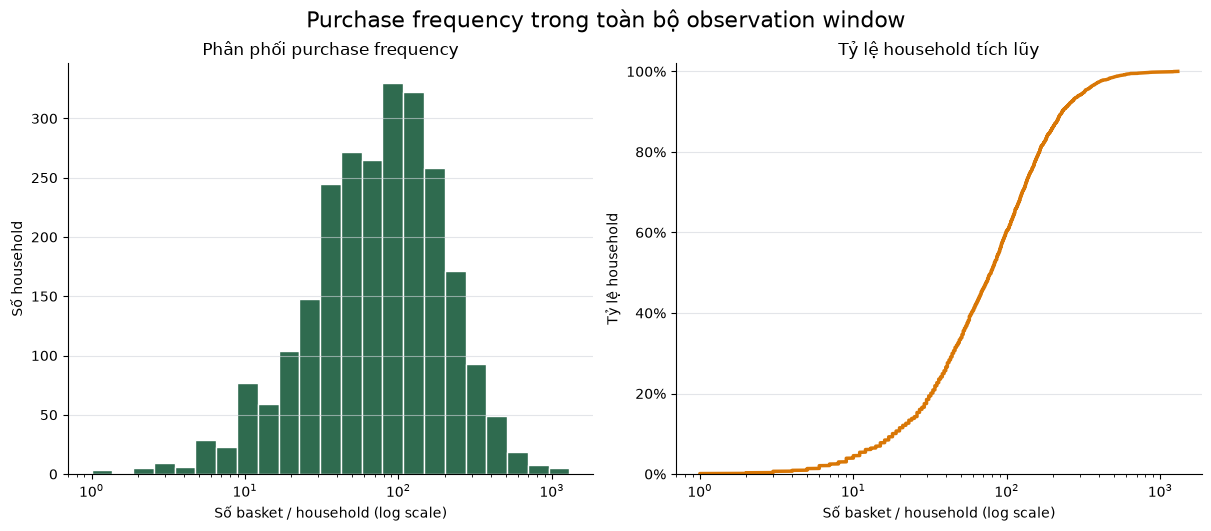

In [3]:
purchase_frequency_figure = plot_purchase_frequency(behavior.households)

## 3. Basket Size, Value & Structure

Bốn góc nhìn được đặt cạnh nhau: số product distinct, số department distinct, customer spend và quan hệ giữa size với value. Biểu đồ chỉ cắt phần hiển thị tại p99; dữ liệu gốc không bị winsorize.

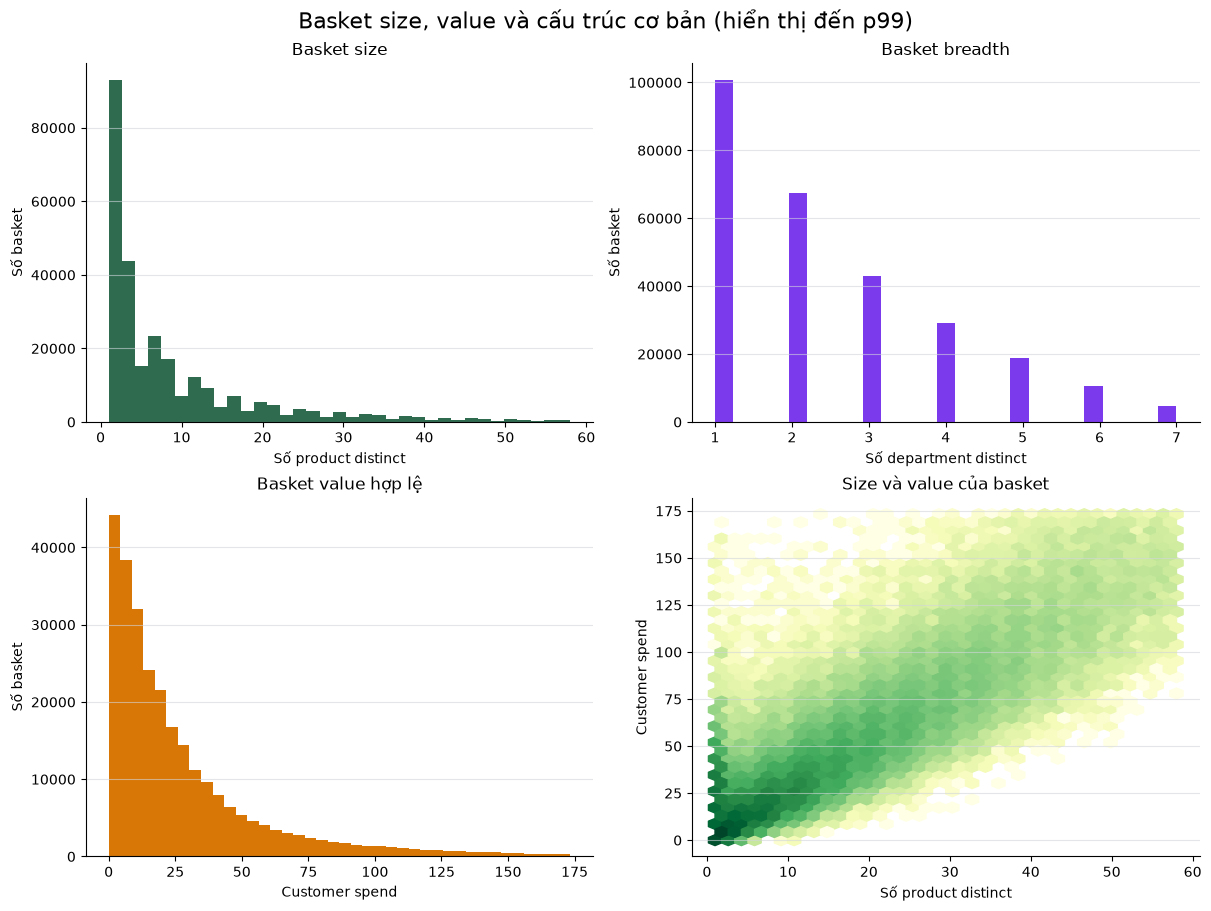

In [4]:
basket_figure = plot_basket_size_value_structure(behavior.baskets)

## 4. Household Spending

Phân rã `total spend = basket count × average basket value`. Đường concentration cho biết chi tiêu tập trung vào nhóm household đầu bảng đến đâu; scatter cho thấy các con đường hành vi khác nhau tạo ra spending.

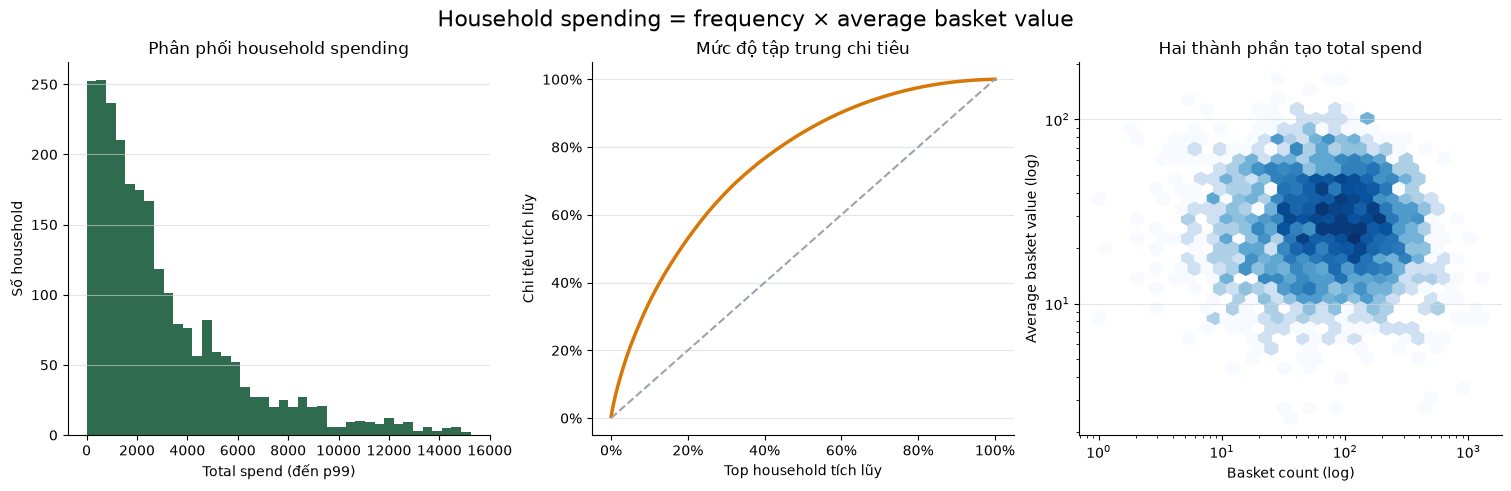

In [5]:
household_spending_figure = plot_household_spending(behavior.households)

## 5. Store Usage

Store breadth đo số store distinct; primary-store share đo mức tập trung basket tại store được dùng nhiều nhất. Concentration luôn được đọc cùng frequency vì household ít basket dễ có primary-store share cao một cách cơ học.

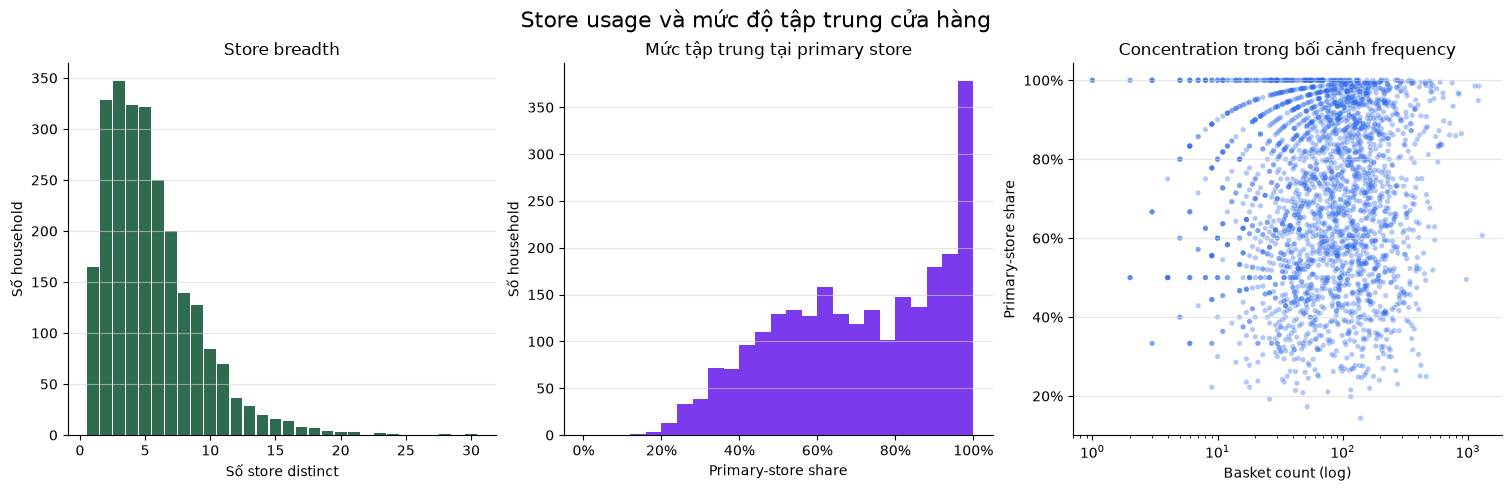

In [6]:
store_usage_figure = plot_store_usage(behavior.households)

## 6. Transaction Discount Usage

Phân tích incidence và intensity ở transaction level, đồng thời so sánh basket value giữa giao dịch có và không có discount. Đây là mô tả usage; không diễn giải discount là nguyên nhân làm basket lớn hơn và không thay thế promotion-response analysis của file 05.

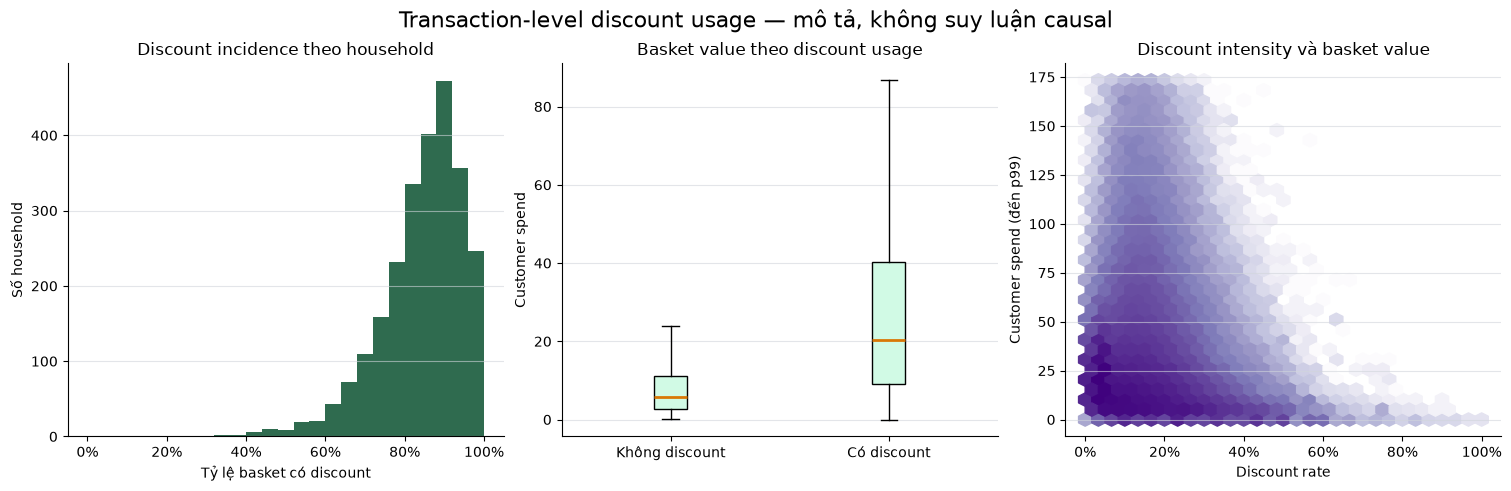

In [7]:
discount_usage_figure = plot_transaction_discount_usage(
    behavior.baskets,
    behavior.households,
)

## 7. Cross-Behavior Analysis

Spearman correlation phù hợp hơn Pearson cho các behavioral metrics lệch mạnh. Heatmap dùng để nhận diện trục hành vi liên hệ hoặc dư thừa; correlation không chứng minh quan hệ nhân quả.

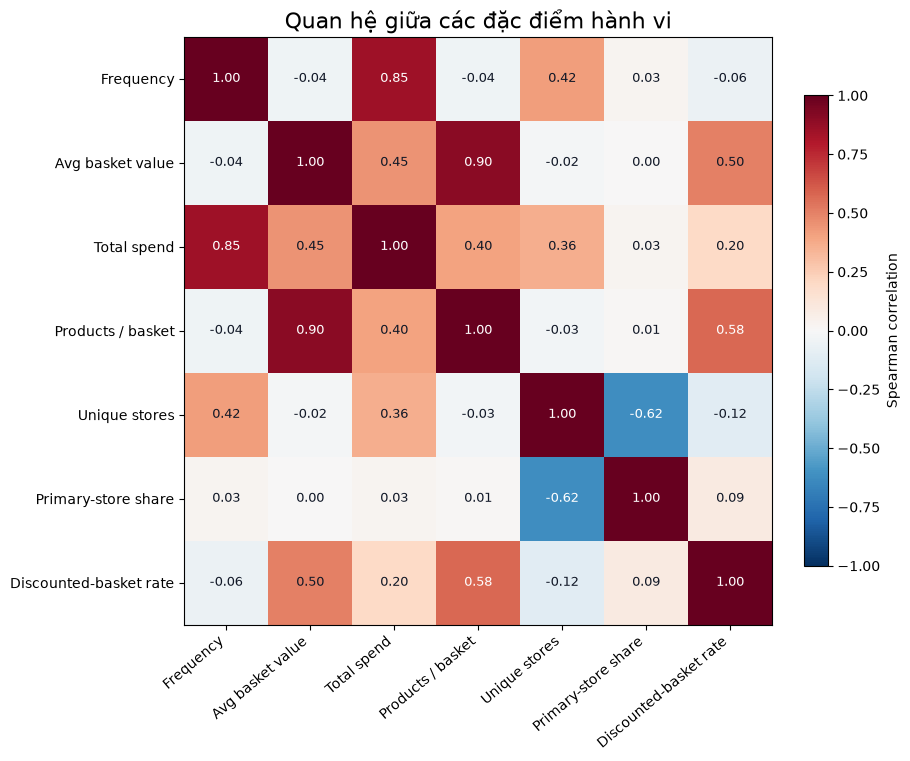

In [8]:
cross_behavior_figure = plot_cross_behavior(behavior.households)

## 8. Behavioral Patterns & Insights

Bốn quadrant frequency × average basket value tạo các pattern mô tả dễ đọc. Đây chưa phải segmentation cuối cùng: chưa kết hợp temporal behavior của file 04, category/promotion behavior của file 05 hoặc kiểm tra độ ổn định theo snapshot.

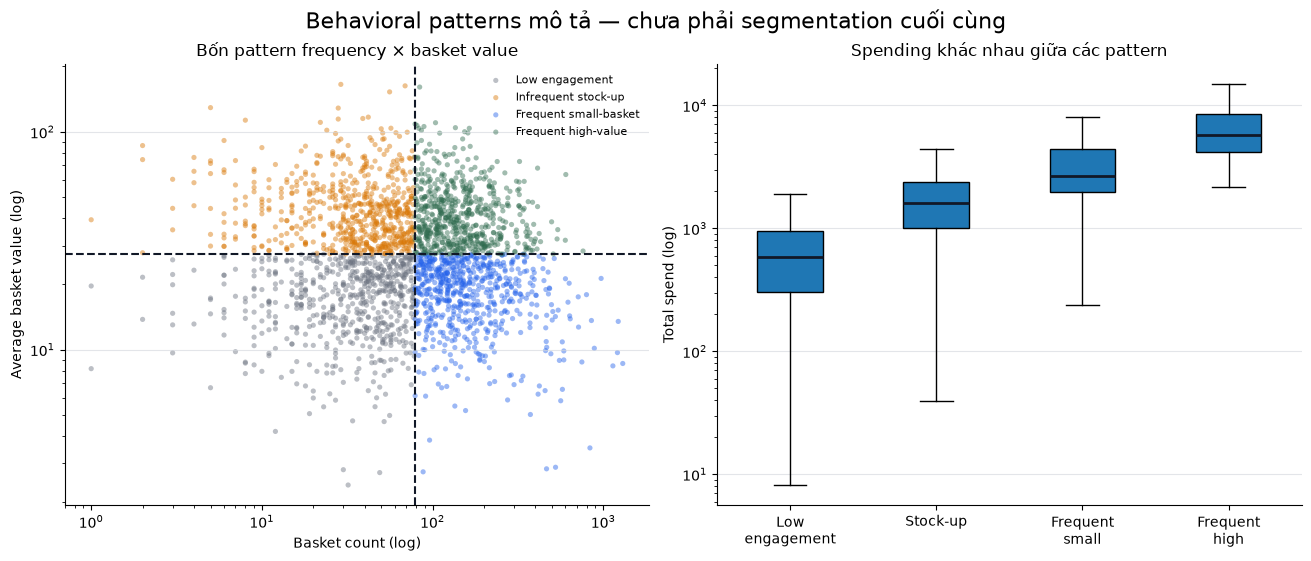

In [9]:
behavioral_patterns_figure = plot_behavioral_patterns(behavior.households)

## Ranh giới phân tích tiếp theo

- File 04: purchase cycle, regularity, recency, continuity, trend và seasonality.
- File 05: category preference, category affinity, promotion sensitivity và response.
- Segmentation tổng hợp chỉ thực hiện sau khi kết hợp bằng chứng từ cả ba notebook.